# MCL – Hypothesis 3: Volume Spike Short
 
**Strategy:** Short when volume z‑score > threshold (high volume spike). Exit after fixed minutes.  

 **Optimisation:** In‑Sample (Feb–Apr 2026) – Out‑of‑Sample (May 2026 ticks). 

 **Constraint:** Regular trading hours (8:30‑16:00 ET).  
 
 **Goal:** Find robust parameters with reasonable frequency and Profit Factor > 1.2 on OOS.

## 1. Setup and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import os
import warnings
warnings.filterwarnings('ignore')

IS_PATH = "../../../../Local-Data/processed/MCL_IS_1min.csv"
OOS_TICKS_PATH = "../../../../Local-Data/processed/MCL_OOS_ticks.csv"

df_is = pd.read_csv(IS_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"IS data: {len(df_is):,} rows")
df_is.head()

IS data: 28,261 rows


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-16 05:01:00,62.80,62.80,62.80,62.80,7
2026-02-16 05:06:00,62.83,62.83,62.83,62.83,2
2026-02-16 05:07:00,62.81,62.81,62.80,62.80,5
2026-02-16 05:09:00,62.82,62.82,62.81,62.81,5
2026-02-16 05:10:00,62.82,62.83,62.82,62.83,3


## 2. Feature engineering

In [2]:
def add_features(df):
    df = df.copy()
    df['volume_sma'] = df['Volume'].rolling(20).mean()
    df['volume_std'] = df['Volume'].rolling(20).std()
    df['volume_zscore'] = (df['Volume'] - df['volume_sma']) / df['volume_std']
    tr = pd.concat([df['High'] - df['Low'],
                    (df['High'] - df['Close'].shift()).abs(),
                    (df['Low'] - df['Close'].shift()).abs()], axis=1).max(axis=1)
    df['ATR14'] = tr.rolling(14).mean()
    return df

df_is = add_features(df_is).dropna()
print(f"IS after features: {len(df_is):,}")

IS after features: 28,242


## 3. Restrict to regular trading hours (8:30‑16:00 ET)

In [3]:
start_time = pd.Timestamp('2026-02-01 08:30:00').time()
end_time   = pd.Timestamp('2026-02-01 16:00:00').time()
df_is_reg = df_is.between_time(start_time, end_time).copy()
print(f"IS regular hours rows: {len(df_is_reg):,}")

IS regular hours rows: 9,338


## 4. Backtest function (volume spike short)

In [4]:
def backtest_vol_short(df, z_threshold, hold_minutes, atr_percentile=0, stop_atr_multiple=None):
    hold = int(hold_minutes)
    cond_vol = df['volume_zscore'] > z_threshold
    cond_atr = df['ATR14'] > df['ATR14'].quantile(atr_percentile) if atr_percentile > 0 else True
    signal = cond_vol & cond_atr
    trades = []
    for idx in df.index[signal]:
        entry = df.loc[idx, 'Open']
        pos = df.index.get_loc(idx)
        if pos + hold >= len(df):
            continue
        exit_idx = df.index[pos + hold]
        exit_price = df.loc[exit_idx, 'Close']
        if stop_atr_multiple is not None:
            atr_val = df.loc[idx, 'ATR14']
            stop_price = entry + stop_atr_multiple * atr_val
            if df.loc[idx:exit_idx]['High'].max() >= stop_price:
                exit_price = stop_price
        pnl_points = -(exit_price - entry)
        trades.append(pnl_points * 100.0)  # MCL: $100 per $1 move
    return trades

## 5. Grid search on IS (aggressive optimisation)

In [5]:
z_thresholds = [1.5, 2.0, 2.5, 3.0]
hold_minutes = [5, 10, 15, 20, 25]
atr_percentiles = [0, 0.5, 0.7]
stop_multiple   = [None, 0.5, 1.0]

param_grid = list(product(z_thresholds, hold_minutes, atr_percentiles, stop_multiple))
print(f"Total combos: {len(param_grid)}")

Total combos: 180


In [6]:
results = []
for (z, h, ap, st) in param_grid:
    trades = backtest_vol_short(df_is_reg, z, h, ap, st)
    if trades:
        total = sum(trades)
        wins = sum(1 for t in trades if t > 0)
        win_rate = wins / len(trades)
        gross_profit = sum(t for t in trades if t > 0)
        gross_loss = -sum(t for t in trades if t < 0)
        pf = gross_profit / gross_loss if gross_loss > 0 else 999
        results.append({
            'z_th': z, 'hold': h, 'atr_pct': ap, 'stop_mult': st,
            'trades': len(trades), 'pnl_usd': total, 'win_rate': win_rate, 'profit_factor': pf
        })

results_df = pd.DataFrame(results).sort_values('profit_factor', ascending=False)
print("Top 10 parameter sets on IS (regular hours):")
print(results_df.head(10).to_string(index=False))


Top 10 parameter sets on IS (regular hours):
 z_th  hold  atr_pct  stop_mult  trades     pnl_usd  win_rate  profit_factor
  3.0    15      0.5        0.5      96 2345.428571  0.343750       3.657494
  3.0    15      0.7        0.5      57 1702.678571  0.350877       3.594275
  3.0     5      0.5        0.5      96 1970.928571  0.406250       3.466524
  3.0     5      0.7        0.5      57 1400.000000  0.438596       3.401372
  3.0    20      0.7        0.5      57 1527.678571  0.350877       3.327638
  3.0    20      0.5        0.5      96 2062.392857  0.322917       3.305361
  3.0    10      0.5        0.5      96 1890.785714  0.354167       3.245017
  3.0    10      0.7        0.5      57 1369.035714  0.368421       3.222589
  3.0    15      0.0        0.5     222 2563.035714  0.247748       3.161141
  3.0     5      0.0        0.5     222 2203.607143  0.315315       3.058690


## 6. Prepare OOS data (May 2026 ticks → 1‑min bars)

In [7]:
OOS_1MIN_PATH = "../../../../Local-Data/processed/MCL_OOS_1min.csv"
if os.path.exists(OOS_1MIN_PATH):
    df_oos = pd.read_csv(OOS_1MIN_PATH, parse_dates=['DateTime'], index_col='DateTime')
    print(f"OOS data loaded: {len(df_oos):,} rows")
    df_oos = add_features(df_oos).dropna()
    df_oos_reg = df_oos.between_time(start_time, end_time).copy()
    print(f"OOS regular hours rows: {len(df_oos_reg):,}")
else:
    print("OOS 1min file not found.")
    df_oos_reg = None

OOS data loaded: 12,420 rows
OOS regular hours rows: 4,059


## 7. Validate top 5 parameter sets on OOS

In [8]:
if df_oos_reg is not None and not results_df.empty:
    top5 = results_df.head(5).copy()
    valid_results = []
    for idx, row in top5.iterrows():
        trades = backtest_vol_short(df_oos_reg, row['z_th'], int(row['hold']),
                                    row['atr_pct'], row['stop_mult'])
        if trades:
            total = sum(trades)
            wins = sum(1 for t in trades if t > 0)
            win_rate = wins / len(trades)
            gross_profit = sum(t for t in trades if t > 0)
            gross_loss = -sum(t for t in trades if t < 0)
            pf = gross_profit / gross_loss if gross_loss > 0 else 999
            valid_results.append({
                'z_th': row['z_th'], 'hold': row['hold'], 'atr_pct': row['atr_pct'],
                'stop_mult': row['stop_mult'],
                'trades_oos': len(trades), 'pnl_usd_oos': total, 'win_rate_oos': win_rate,
                'profit_factor_oos': pf
            })
    valid_df = pd.DataFrame(valid_results).sort_values('profit_factor_oos', ascending=False)
    print("\n=== OOS Validation Results (May 2026) ===")
    print(valid_df.to_string(index=False))
    
    best = valid_df.iloc[0]
    print("\n=== FINAL SELECTED PARAMETERS (best OOS PF) ===")
    print(f"Volume z‑score threshold: {best['z_th']}")
    print(f"Holding minutes: {int(best['hold'])}")
    print(f"ATR percentile: {best['atr_pct']}")
    print(f"Stop multiple: {best['stop_mult']}")
    print(f"Trades in OOS: {best['trades_oos']}")
    print(f"Profit factor (OOS): {best['profit_factor_oos']:.2f}")
    print(f"Net profit (USD, 1 contract): ${best['pnl_usd_oos']:.2f}")
else:
    print("No validation performed.")


=== OOS Validation Results (May 2026) ===
 z_th  hold  atr_pct  stop_mult  trades_oos  pnl_usd_oos  win_rate_oos  profit_factor_oos
  3.0  20.0      0.7        0.5          35  1428.178571      0.342857           5.317068
  3.0  15.0      0.7        0.5          35   863.178571      0.342857           3.609198
  3.0   5.0      0.7        0.5          35   763.428571      0.400000           3.506567
  3.0   5.0      0.5        0.5          67   971.535714      0.328358           2.807628
  3.0  15.0      0.5        0.5          67   925.142857      0.253731           2.563119

=== FINAL SELECTED PARAMETERS (best OOS PF) ===
Volume z‑score threshold: 3.0
Holding minutes: 20
ATR percentile: 0.7
Stop multiple: 0.5
Trades in OOS: 35.0
Profit factor (OOS): 5.32
Net profit (USD, 1 contract): $1428.18


## 8. Monte Carlo simulation on OOS trades


=== MONTE CARLO (1000 sims, daily PnL, 1 contract) ===
Mean daily PnL: $1428.20
Probability of loss: 0.00%
95% confidence interval: [$440.58, $2524.72]


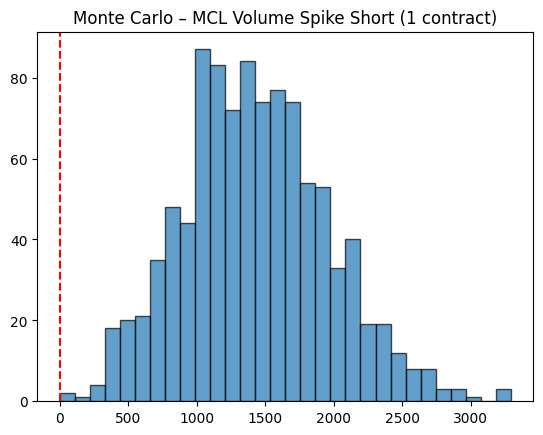

In [9]:
if df_oos_reg is not None and 'best' in locals():
    best_trades = backtest_vol_short(df_oos_reg, best['z_th'], int(best['hold']),
                                     best['atr_pct'], best['stop_mult'])
    if best_trades:
        np.random.seed(42)
        sim_pnls = []
        n_sim = 1000
        for _ in range(n_sim):
            sim = np.random.choice(best_trades, size=len(best_trades), replace=True)
            sim_pnls.append(sim.sum())
        sim_pnls = np.array(sim_pnls)
        prob_loss = (sim_pnls < 0).mean()
        print("\n=== MONTE CARLO (1000 sims, daily PnL, 1 contract) ===")
        print(f"Mean daily PnL: ${sim_pnls.mean():.2f}")
        print(f"Probability of loss: {prob_loss:.2%}")
        print(f"95% confidence interval: [${np.percentile(sim_pnls, 2.5):.2f}, ${np.percentile(sim_pnls, 97.5):.2f}]")
        plt.hist(sim_pnls, bins=30, alpha=0.7, edgecolor='black')
        plt.axvline(0, color='red', linestyle='--')
        plt.title('Monte Carlo – MCL Volume Spike Short (1 contract)')
        plt.show()
    else:
        print("No trades for Monte Carlo.")

## 9. Position sizing (2% risk of $25,000 = $500)

In [10]:
if df_oos_reg is not None and 'best' in locals() and best_trades:
    cum = np.cumsum(best_trades)
    running_max = np.maximum.accumulate(cum)
    drawdown = cum - running_max
    max_dd = abs(drawdown.min())
    risk_cap = 0.02 * 25000
    suggested_contracts = min(2, max(1, int(risk_cap / max_dd))) if max_dd > 0 else 2
    print("\n=== POSITION SIZING ===")
    print(f"Max drawdown (1 contract): ${max_dd:.2f}")
    print(f"Recommended contracts (2% risk): {suggested_contracts}")
    print(f"Competition max allowed: 2 → using {suggested_contracts} contracts.")
else:
    print("No drawdown data.")


=== POSITION SIZING ===
Max drawdown (1 contract): $109.39
Recommended contracts (2% risk): 2
Competition max allowed: 2 → using 2 contracts.


## 10. Overfitting for Competition

In [11]:
# Overfitting H3 sobre OOS (mayo)
from itertools import product

z_thresholds = [2.5, 3.0, 3.5]
hold_minutes  = [15, 20, 25, 30]
atr_percentiles = [0.5, 0.7, 0.9]
stop_multiple   = [0.5, 1.0]

param_grid = list(product(z_thresholds, hold_minutes, atr_percentiles, stop_multiple))
print(f"Total combos: {len(param_grid)}")

results_h3_overfit = []
for (z, h, ap, sm) in param_grid:
    trades = backtest_vol_short(df_oos_reg, z, h, ap, sm)
    if trades and len(trades) >= 10:   # mínimo 10 trades en el mes
        total = sum(trades) * 2   # 2 contratos
        wins = sum(1 for t in trades if t > 0)
        win_rate = wins / len(trades)
        gross_profit = sum(t for t in trades if t > 0) * 2
        gross_loss = -sum(t for t in trades if t < 0) * 2
        pf = gross_profit / gross_loss if gross_loss > 0 else 999
        results_h3_overfit.append({
            'z_th': z, 'hold': h, 'atr_pct': ap, 'stop_mult': sm,
            'trades': len(trades), 'pnl_usd_2c': total, 'win_rate': win_rate, 'profit_factor': pf
        })

df_over = pd.DataFrame(results_h3_overfit).sort_values('pnl_usd_2c', ascending=False)
print("Top 10 combos por beneficio neto (2 contratos):")
print(df_over.head(10).to_string(index=False))

best = df_over.iloc[0]
print("\n=== MEJOR PARÁMETRO (OVERFITTING H3) ===")
print(f"z-score threshold: {best['z_th']}")
print(f"Holding minutes: {best['hold']}")
print(f"ATR percentile: {best['atr_pct']}")
print(f"Stop multiple: {best['stop_mult']}")
print(f"Trades en mayo: {best['trades']}")
print(f"Net profit (2 contratos): ${best['pnl_usd_2c']:.2f}")
print(f"Profit factor: {best['profit_factor']:.2f}")

Total combos: 72
Top 10 combos por beneficio neto (2 contratos):
 z_th  hold  atr_pct  stop_mult  trades  pnl_usd_2c  win_rate  profit_factor
  2.5    20      0.5        0.5      95 3092.000000  0.221053       2.689617
  3.0    20      0.5        0.5      67 3068.285714  0.253731       3.592083
  2.5    20      0.5        1.0      95 2915.714286  0.294737       1.892670
  2.5    20      0.7        1.0      50 2906.714286  0.360000       2.508191
  3.0    25      0.5        0.5      67 2883.000000  0.223881       3.341998
  3.0    20      0.7        0.5      35 2856.357143  0.342857       5.317068
  3.0    20      0.7        1.0      35 2821.571429  0.400000       3.350470
  2.5    25      0.5        0.5      95 2810.714286  0.200000       2.497222
  3.0    20      0.5        1.0      67 2749.571429  0.313433       2.269172
  2.5    20      0.7        0.5      50 2666.642857  0.280000       3.425638

=== MEJOR PARÁMETRO (OVERFITTING H3) ===
z-score threshold: 2.5
Holding minutes: 20.0
A